# 离散 Delta 对冲模拟

## 1. 研究问题与假设

用股票和现金账户复制一份欧式看涨期权，观察：

- 调仓间隔为 1、7、30 天时，复制误差如何变化？
- 股票真实漂移率从 +10% 变为 −10% 时，理论定价与离散对冲表现如何变化？

假设股票服从常波动率 GBM，无股息、无交易成本，允许碎股交易；借款与存款采用相同的连续复利利率。365 表示一年划分为 365 个模拟间隔，7 天和 30 天是固定间隔，未处理真实交易日历。

本文件已保存一次完整运行的输出。重新运行时请从上到下运行全部单元；修改参数后也应重新运行全部单元。

## 2. 参数

初始股价与行权价均为 100，期限 1 年，年化波动率 20%，无风险利率 5%。每种 drift 模拟 1000 条路径，种子为 42。沿用学习时的变量名 P、step、drift。


In [1]:
import csv
from pathlib import Path
from statistics import NormalDist

import numpy as np
import matplotlib.pyplot as plt

P = 100             # 初始股价
K = 100             # 行权价
sigma = 0.20        # 年化波动率
T = 1               # 一年到期
step = 365          # 一年分为 365 个时间间隔
r = 0.05            # 年化无风险利率
path_count = 1000
seed = 42
intervals = [1, 7, 30]
drifts = [0.10, -0.10]
dt = T / step
normal = NormalDist()


In [2]:
result_dir = Path("results")
result_dir.mkdir(exist_ok=True)


## 3. 初始价格与持仓

记剩余期限为 $\tau$，当前股价为 $S$：

$$d_1=\frac{\ln(S/K)+(r+\sigma^2/2)\tau}{\sigma\sqrt{\tau}},\qquad d_2=d_1-\sigma\sqrt{\tau}.$$

$$C=S\Phi(d_1)-Ke^{-r\tau}\Phi(d_2),\qquad \Delta=\Phi(d_1).$$

初始持有 $\Delta_0$ 股，现金 $B_0=C_0-\Delta_0P$。负现金表示借款。初始组合价值等于期权理论价格，且对股价小幅变化的敏感度相同。真实漂移率不出现在这两个公式中。


In [3]:
d1 = (np.log(P / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)
call_price = P * normal.cdf(d1) - K * np.exp(-r * T) * normal.cdf(d2)
delta = normal.cdf(d1)
initial_cash = call_price - delta * P

print(f"Initial option price: {call_price:.10f}")
print(f"Initial delta:        {delta:.10f}")
print(f"Initial cash:         {initial_cash:.10f}")


Initial option price: 10.4505835722
Initial delta:        0.6368306512
Initial cash:         -53.2324815454


## 4. 路径生成与自融资对冲

$$S_{t+\Delta t}=S_t\exp\left[(\mu-\sigma^2/2)\Delta t+\sigma\sqrt{\Delta t}Z\right],\quad Z\sim N(0,1).$$

这是 GBM 在网格时点之间的精确更新；复制误差来自离散调仓，而非该更新公式的 Euler 离散误差。

每个时点先更新现金 $B\leftarrow Be^{r\Delta t}$。如果需要调仓，则计算新的 Delta，并执行：

$$B\leftarrow B-(\Delta_{\rm new}-\Delta_{\rm old})S.$$

买股消耗现金，卖股增加现金。调仓瞬间组合总价值保持不变；不通过补钱让现金余额强行回到理论值。循环只到到期前，到期不计算剩余期限为零的 Delta。

最终误差 $E=V_T-\max(S_T-K,0)$；正值表示支付期权收益后有盈余，负值表示不足。函数沿用前面定义的模型参数，修改参数后要重新运行初始定价。


In [4]:
def generate_path(rng, drift):
    """按 GBM 的精确更新公式生成一条路径，包含初始价格。"""
    prices = [P]
    for i in range(step):
        Z = rng.standard_normal()
        next_price = prices[-1] * np.exp(
            (drift - 0.5 * sigma**2) * dt
            + sigma * np.sqrt(dt) * Z
        )
        prices.append(next_price)
    return np.array(prices)


def hedge_error(prices, rebalance_every):
    """沿用上面的模型参数，返回自融资组合的到期复制误差。"""
    shares = delta
    cash = call_price - shares * P

    for i in range(1, step):
        cash *= np.exp(r * dt)  # 不论是否调仓，现金每天计息
        if i % rebalance_every != 0:
            continue

        current_price = prices[i]
        remaining_time = T - i * dt
        current_d1 = (
            np.log(current_price / K)
            + (r + 0.5 * sigma**2) * remaining_time
        ) / (sigma * np.sqrt(remaining_time))
        new_delta = normal.cdf(current_d1)

        cash -= (new_delta - shares) * current_price
        shares = new_delta

    # 最后一个间隔只计息，到期不再计算 Delta
    cash *= np.exp(r * dt)
    final_value = shares * prices[-1] + cash
    payoff = max(prices[-1] - K, 0)
    return final_value - payoff


## 5. 批量实验与评价指标

每条路径分别测试三种调仓频率。两种 drift 重新使用相同种子，使对应路径使用相同随机冲击；每种 drift 内不重置生成器。

$$\overline E=\frac1M\sum_{j=1}^M E_j,\qquad \mathrm{RMSE}=\sqrt{\frac1M\sum_{j=1}^M E_j^2}.$$

平均误差反映偏向盈余还是不足；RMSE 避免正负误差抵消，越小表示总体复制越准确。


In [5]:
all_errors = {}
example_paths = {}

for drift in drifts:
    # 每种 drift 重新使用同一种子，使两组实验配对使用相同随机冲击。
    # 同一组实验内，生成器必须放在路径循环外。
    rng = np.random.default_rng(seed)
    errors = {interval: [] for interval in intervals}

    for path_number in range(path_count):
        prices = generate_path(rng, drift)
        if path_number == 0:
            example_paths[drift] = prices.copy()
        for interval in intervals:
            errors[interval].append(hedge_error(prices, interval))

    all_errors[drift] = {
        interval: np.array(values) for interval, values in errors.items()
    }

# 全部模拟完成后再统计，避免在路径循环中反复计算。
summary = []
print("Drift   Interval   Mean error     RMSE")
for drift in drifts:
    for interval in intervals:
        values = all_errors[drift][interval]
        mean_error = float(np.mean(values))
        rmse = float(np.sqrt(np.mean(values**2)))
        summary.append({
            "drift": drift, "interval_days": interval,
            "mean_error": mean_error, "rmse": rmse,
        })
        print(f"{drift:+.0%}    {interval:>3}        {mean_error:>8.4f}   {rmse:>8.4f}")


Drift   Interval   Mean error     RMSE
+10%      1         -0.0130     0.3533
+10%      7          0.0026     0.8922
+10%     30          0.0699     1.8667
-10%      1         -0.0132     0.3625
-10%      7         -0.0485     0.9375
-10%     30         -0.0504     1.7658


## 6. 图表

两条示例路径共享随机冲击，仅 drift 不同。直方图六个面板采用相同分组边界与坐标范围，红线表示零误差。RMSE 柱状图便于比较总体复制准确度。

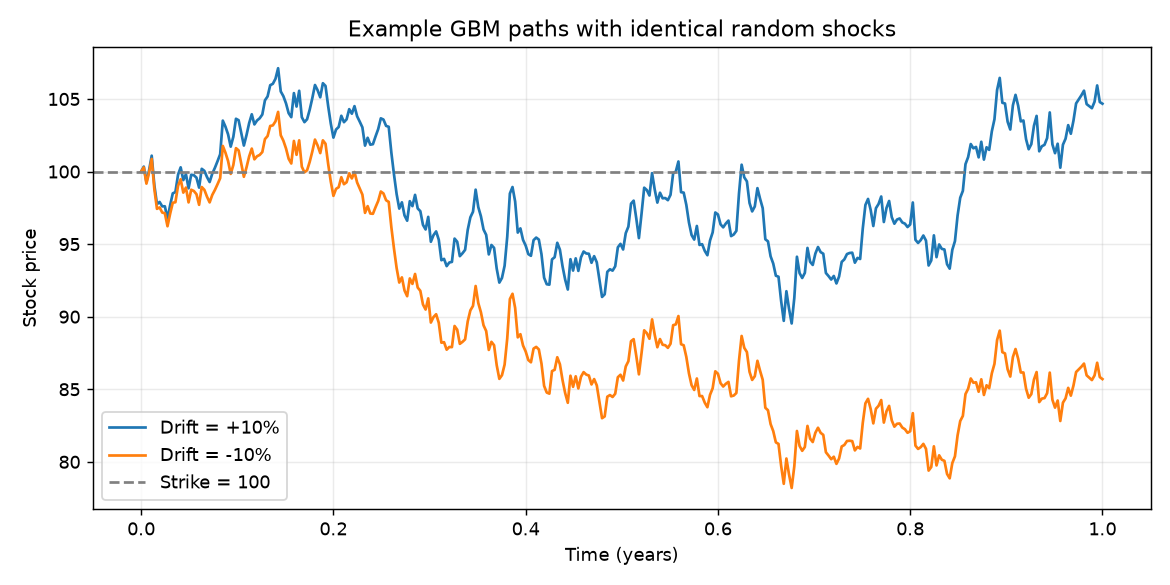

In [6]:
times = np.linspace(0, T, step + 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
for drift in drifts:
    ax.plot(times, example_paths[drift], label=f"Drift = {drift:+.0%}")
ax.axhline(K, color="gray", linestyle="--", label="Strike = 100")
ax.set(xlabel="Time (years)", ylabel="Stock price",
       title="Example GBM paths with identical random shocks")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(result_dir / "example_paths.png", dpi=160)
plt.show()


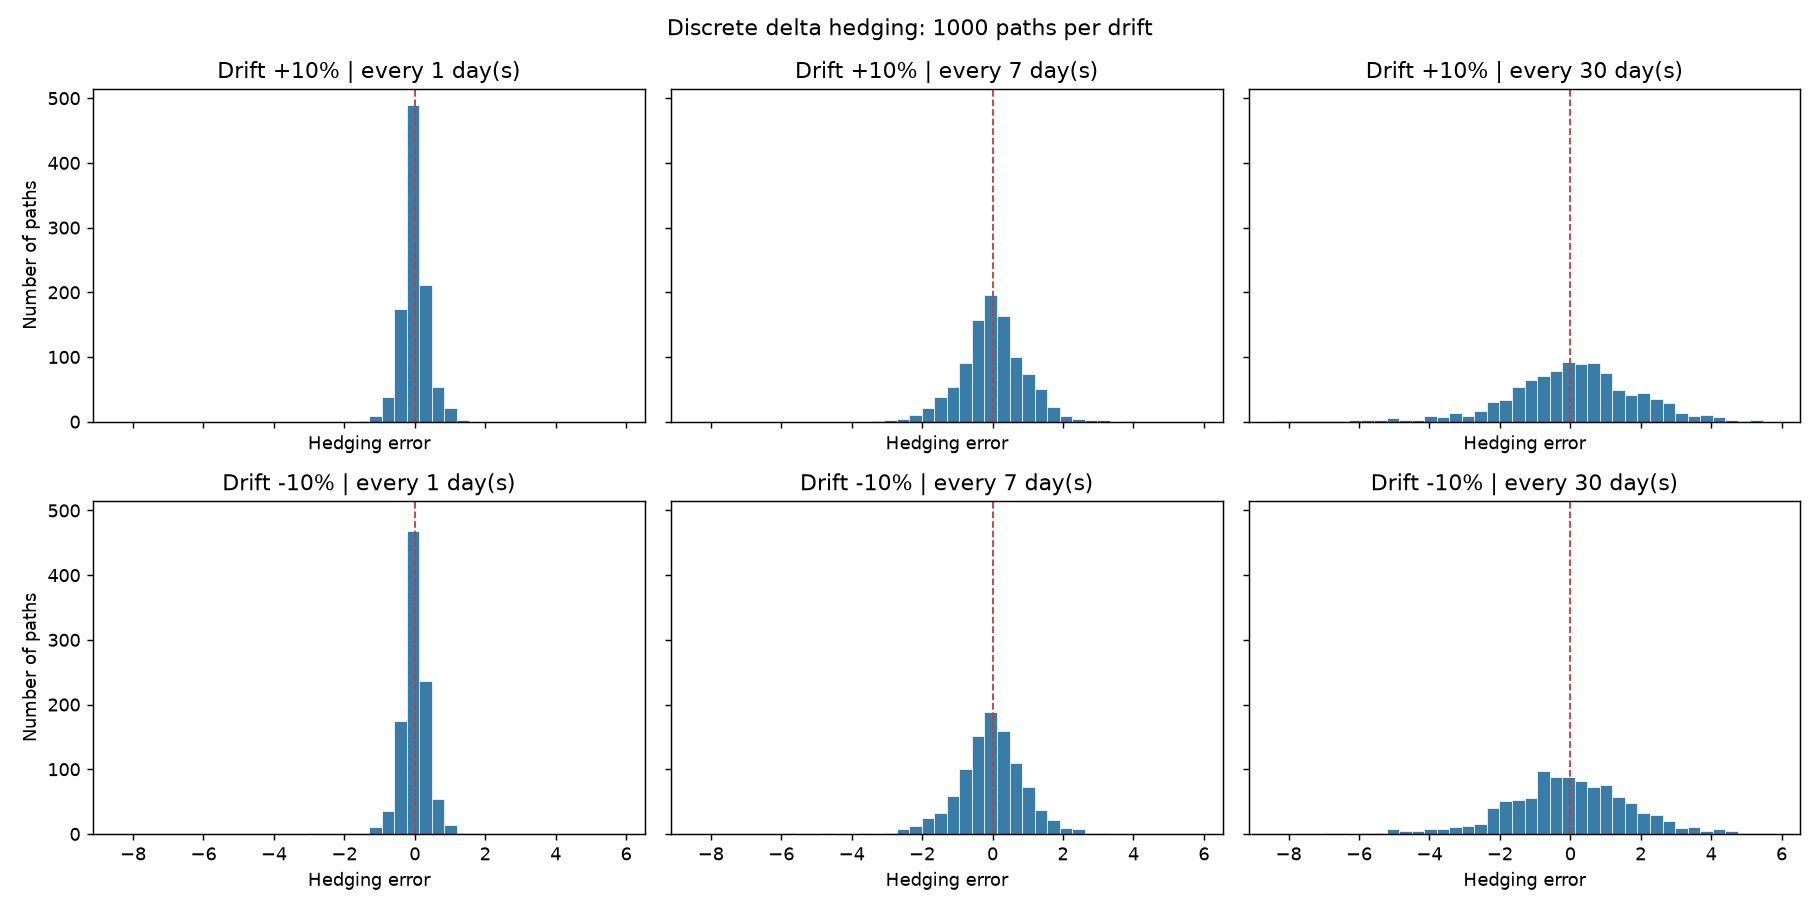

In [7]:
combined = np.concatenate([
    all_errors[drift][interval] for drift in drifts for interval in intervals
])
bins = np.linspace(combined.min(), combined.max(), 41)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
for row, drift in enumerate(drifts):
    for col, interval in enumerate(intervals):
        ax = axes[row, col]
        ax.hist(all_errors[drift][interval], bins=bins,
                color="#397ca8", edgecolor="white", linewidth=0.4)
        ax.axvline(0, color="#c33c3c", linestyle="--", linewidth=1)
        ax.set_title(f"Drift {drift:+.0%} | every {interval} day(s)")
        ax.set_xlabel("Hedging error")
        if col == 0:
            ax.set_ylabel("Number of paths")
fig.suptitle(f"Discrete delta hedging: {path_count} paths per drift")
fig.tight_layout()
fig.savefig(result_dir / "error_distributions.png", dpi=160)
plt.show()


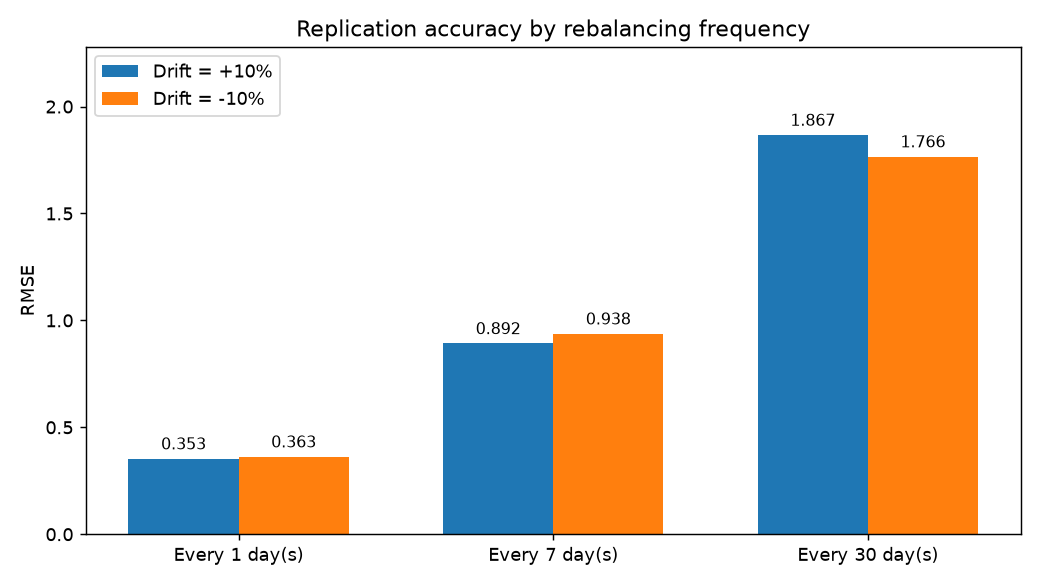

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(intervals))
width = 0.35
for offset, drift in zip([-width / 2, width / 2], drifts):
    values = [row["rmse"] for row in summary if row["drift"] == drift]
    bars = ax.bar(x + offset, values, width, label=f"Drift = {drift:+.0%}")
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_xticks(x, [f"Every {n} day(s)" for n in intervals])
ax.set(ylabel="RMSE", title="Replication accuracy by rebalancing frequency")
ax.set_ylim(0, max(row["rmse"] for row in summary) * 1.22)
ax.legend()
fig.tight_layout()
fig.savefig(result_dir / "rmse_comparison.png", dpi=160)
plt.show()


## 7. 结论与局限

1. 本次实验中，两种 drift 下 RMSE 均随调仓间隔缩短而下降。更频繁更新持仓，使持股数量更及时地跟随 Delta。
2. 平均误差接近零不等于逐条路径准确，例如 +10% drift 下每周调仓的平均误差更接近零，但 RMSE 大于每天调仓。
3. 真实 drift 不影响初始 Black–Scholes 价格和 Delta；它改变路径及离散对冲误差分布。本次改变 drift 后，RMSE 没有统一增大或减小。
4. 连续调仓的理想模型能够复制期权，离散调仓则留下随机误差，不能将单条路径的盈余视为稳定盈利策略。

局限：路径生成与定价采用相同 GBM 模型，未考虑交易成本、随机波动率、跳跃、股息、融资约束或真实行情。1000 条路径有抽样误差，未计算置信区间，不能把两组 drift 间的小差异当作稳定规律。本项目验证模型内的复制行为，不构成真实市场表现验证。


## 8. 导出数据

`summary.csv` 保存六行统计结果；`path_errors.csv` 保存两种 drift 各 1000 条路径的误差。图表已在上面的单元保存为 PNG。

In [9]:
with (result_dir / "summary.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

with (result_dir / "path_errors.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["drift", "path_id", "error_1_day", "error_7_days", "error_30_days"])
    for drift in drifts:
        for j in range(path_count):
            writer.writerow([drift, j + 1] + [
                all_errors[drift][interval][j] for interval in intervals
            ])

print("Saved figures and CSV files to:", result_dir.resolve())


Saved figures and CSV files to: results/
